# Modelagem Preditiva e Graph-Enhanced Machine Learning

Nas fases anteriores, foram realizadas a EDA/auditoria tabular (notebook 02) e extraída a anatomia topológica da rede via Teoria de Grafos, calculando *PageRank*, *Betweenness* e *Degrees*, por fim persistindo tudo no banco SQLite (notebook 03).

Nesta iremos treinar e avaliar um modelo preditivo de ML para detecção de lavagem de dinheiro (`Is_Laundering`). Para validar o valor do projeto, vamos comparar duas abordagens:

* Modelo Baseline: Treinado apenas com atributos transacionais tabulares.

* Modelo Graph-Enhanced: Treinado com atributos tabulares + métricas topológicas de rede.

O objetivo é provar que a incorporação da rede expõe padrões invisíveis e eleva a precisão preditiva do sistema.

---

## Consolidação do Dataset: Cruzamento Tabular + Topológico

Começamos com a execução da consulta SQL que reconstrói a base de transações e traz, via `LEFT JOIN`, as métricas de rede tanto para a conta de origem quanto para a conta de destino de cada transação.

In [10]:
import os 
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração de estilo visual
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

# Conectando ao banco SQLite
DB_PATH = "../data/aml_network.db"
conn = sqlite3.connect(DB_PATH)

print("Consolidando dados tabulares com as métricas topológicas do banco.")

# Query de cruzamento (origem e destino enriquecidos com features de grafo)
query_dataset = """
    SELECT 
        t.Timestamp,
        t.From_Bank,
        t.Account,
        t.To_Bank,
        t."Account_1" as Target_Account,
        t.Amount_Received,
        t.Amount_Paid,
        t.Receiving_Currency,
        t.Payment_Currency,
        t.Payment_Format,
        t.Is_Laundering,
        -- Métricas da Conta de Origem (Source)
        COALESCE(m_src.PageRank, 0) as src_pagerank,
        COALESCE(m_src.Betweenness, 0) as src_betweenness,
        COALESCE(m_src.In_Degree, 0) as src_in_degree,
        COALESCE(m_src.Out_Degree, 0) as src_out_degree,
        -- Métricas da Conta de Destino (Target)
        COALESCE(m_tgt.PageRank, 0) as tgt_pagerank,
        COALESCE(m_tgt.Betweenness, 0) as tgt_betweenness,
        COALESCE(m_tgt.In_Degree, 0) as tgt_in_degree,
        COALESCE(m_tgt.Out_Degree, 0) as tgt_out_degree
    FROM transacoes t
    LEFT JOIN contas_metricas_topologicas m_src ON t.Account = m_src.Account
    LEFT JOIN contas_metricas_topologicas m_tgt ON t."Account_1" = m_tgt.Account;
"""

df_model = pd.read_sql(query_dataset, conn)
conn.close()

print(f"Dataset consolidado com sucesso!")
print(f"\nFormato final da base para modelagem: {df_model.shape[0]:,} linhas e {df_model.shape[1]} colunas.")
print(f"Total de fraudes na base: {df_model['Is_Laundering'].sum():,}")
display(df_model)

Consolidando dados tabulares com as métricas topológicas do banco.
Dataset consolidado com sucesso!

Formato final da base para modelagem: 5,078,345 linhas e 19 colunas.
Total de fraudes na base: 5,177


,Timestamp,From_Bank,Account,To_Bank,Target_Account,Amount_Received,Amount_Paid,Receiving_Currency,Payment_Currency,Payment_Format,Is_Laundering,src_pagerank,src_betweenness,src_in_degree,src_out_degree,tgt_pagerank,tgt_betweenness,tgt_in_degree,tgt_out_degree
0,2022/09/01 00:20,10,8000EBD30,10,8000EBD30,3697.340000,3697.340000,US Dollar,US Dollar,Reinvestment,0,0.000008,0.0,0,1,0.000008,0.0,0,1
1,2022/09/01 00:20,3208,8000F4580,1,8000F5340,0.010000,0.010000,US Dollar,US Dollar,Cheque,0,0.000000,0.0,0,0,0.000008,0.0,0,1
2,2022/09/01 00:00,3209,8000F4670,3209,8000F4670,14675.570000,14675.570000,US Dollar,US Dollar,Reinvestment,0,0.000000,0.0,0,0,0.000000,0.0,0,0
3,2022/09/01 00:02,12,8000F5030,12,8000F5030,2806.970000,2806.970000,US Dollar,US Dollar,Reinvestment,0,0.000739,0.0,20,1,0.000739,0.0,20,1
4,2022/09/01 00:06,10,8000F5200,10,8000F5200,36682.970000,36682.970000,US Dollar,US Dollar,Reinvestment,0,0.000008,0.0,0,1,0.000008,0.0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5078340,2022/09/10 23:57,54219,8148A6631,256398,8148A8711,0.154978,0.154978,Bitcoin,Bitcoin,Bitcoin,0,0.000000,0.0,0,0,0.000000,0.0,0,0
5078341,2022/09/10 23:35,15,8148A8671,256398,8148A8711,0.108128,0.108128,Bitcoin,Bitcoin,Bitcoin,0,0.000000,0.0,0,0,0.000000,0.0,0,0
5078342,2022/09/10 23:52,154365,8148A6771,256398,8148A8711,0.004988,0.004988,Bitcoin,Bitcoin,Bitcoin,0,0.000000,0.0,0,0,0.000000,0.0,0,0
5078343,2022/09/10 23:46,256398,8148A6311,256398,8148A8711,0.038417,0.038417,Bitcoin,Bitcoin,Bitcoin,0,0.000000,0.0,0,0,0.000000,0.0,0,0


A base unificada está estruturada. Temos o histórico transacional completo cruzado bidirecionalmente com as métricas de rede (origem e destino), preservando intactos os 5.177 casos de fraude (`Is_Laundering = 1`) em meio a mais de 5 milhões de registros normais. O dataset está pronto para a engenharia de features e split de treino/teste.

## O Modelo Baseline - Apenas Dados Tabulares

Antes de testar o poder das redes, precisamos estabelecer o ponto de partida (Baseline), treinando um modelo preditivo (`XGBoost`) utilizando apenas as variáveis tabulares tradicionais (valores transacionais, moedas e formato de pagamento). 

O objetivo é ver até onde um modelo convencional consegue chegar sozinho, para depois medir o salto de performance que o ecossistema de grafos irá proporcionar.

---

*Nota: Por que o XGBoost?*

Para este baseline tabular, alternativas comuns foram descartadas por motivos específicos:

* Regressão Logística: Descartada por sua linearidade restrita. O crime financeiro opera combinando variáveis de forma não-linear (ex: valores específicos cruzados com canais de pagamento), o que faria um modelo linear sofrer de miopia severa.

* Árvore de Decisão Simples: Descartada por ser altamente instável e propensa a *overfitting* em bases de dados massivas.

* XGBoost: Escolhido por ser considerado o padrão-ouro moderno para dados tabulares. Ele lida nativamente com não-linearidades, processa milhões de linhas com alta performance via paralelização e oferece o parâmetro `scale_pos_weight`, essencial para equilibrar o custo de erros em classes extremamente raras (como fraudes).

Preparando os dados e definindo as features do Baseline Tabular.
Treino: 4,062,676 linhas | Teste: 1,015,669 linhas
Fraudes no treino: 4,142 (0.1020%)
Fraudes no teste:  1,035 (0.1019%) - (Estratificação auditada)

Treinando o XGBoost Baseline Tabular (scale_pos_weight = 979.85).

--- PERFORMANCE DO MODELO BASELINE (APENAS TABULAR) ---
PR-AUC Score: 0.0469

Relatório de Classificação:
              precision    recall  f1-score   support

           0       1.00      0.92      0.96   1014634
           1       0.01      0.88      0.02      1035

    accuracy                           0.92   1015669
   macro avg       0.51      0.90      0.49   1015669
weighted avg       1.00      0.92      0.96   1015669



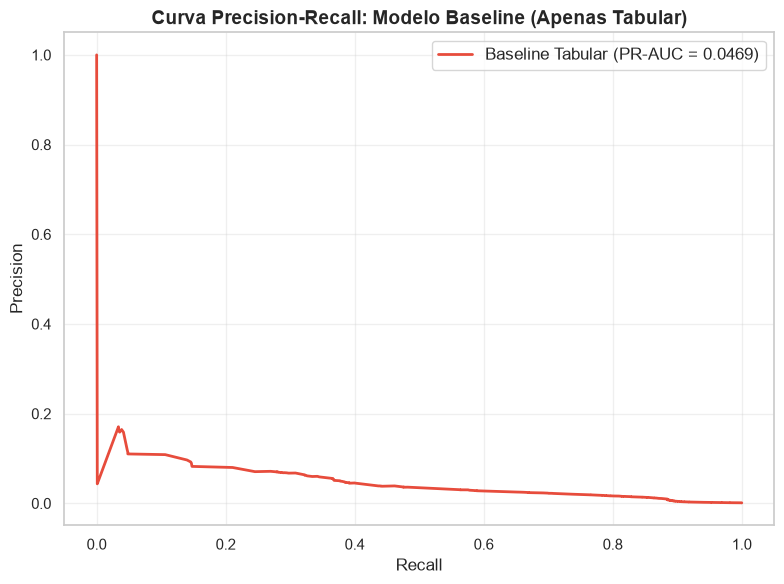

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, precision_recall_curve, auc
import xgboost as xgb
import warnings
warnings.filterwarnings('ignore')

print("Preparando os dados e definindo as features do Baseline Tabular.")

tabular_features = [
    'Amount_Received', 'Amount_Paid', 
    'Receiving_Currency', 'Payment_Currency', 'Payment_Format'
]

df_encoded = pd.get_dummies(df_model[tabular_features + ['Is_Laundering']], drop_first=True)

X_baseline = df_encoded.drop(columns=['Is_Laundering'])
y = df_encoded['Is_Laundering']

# Divisão treino/teste com estratificação auditada
X_train, X_test, y_train, y_test = train_test_split(
    X_baseline, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Treino: {X_train.shape[0]:,} linhas | Teste: {X_test.shape[0]:,} linhas")
print(f"Fraudes no treino: {y_train.sum():,} ({y_train.mean():.4%})")
print(f"Fraudes no teste:  {y_test.sum():,} ({y_test.mean():.4%}) - (Estratificação auditada)")

# Cálculo do scale_pos_weight
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_weight = neg_count / pos_count if pos_count > 0 else 1

print(f"\nTreinando o XGBoost Baseline Tabular (scale_pos_weight = {scale_weight:.2f}).")

model_baseline = xgb.XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    scale_pos_weight=scale_weight,
    random_state=42,
    n_jobs=-1
)

model_baseline.fit(X_train, y_train)

# Predições e Métricas
y_pred_baseline = model_baseline.predict(X_test)
y_prob_baseline = model_baseline.predict_proba(X_test)[:, 1]

precision, recall, _ = precision_recall_curve(y_test, y_prob_baseline)
pr_auc_baseline = auc(recall, precision)

print("\n--- PERFORMANCE DO MODELO BASELINE (APENAS TABULAR) ---")
print(f"PR-AUC Score: {pr_auc_baseline:.4f}")
print("\nRelatório de Classificação:")
print(classification_report(y_test, y_pred_baseline))

# Plotando a Curva Precision-Recall do Baseline para futura comparação
plt.figure(figsize=(8, 6))
plt.plot(recall, precision, label=f'Baseline Tabular (PR-AUC = {pr_auc_baseline:.4f})', color='#e74c3c', lw=2)
plt.xlabel('Recall', fontsize=12)
plt.ylabel('Precision', fontsize=12)
plt.title('Curva Precision-Recall: Modelo Baseline (Apenas Tabular)', fontsize=14, fontweight='bold')
plt.legend(loc='upper right', fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Salvando a imagem
output_dir = os.path.join("..", "output")
os.makedirs(output_dir, exist_ok=True)
caminho_imagem = os.path.join(output_dir, "curva_pr_baselinetabular.png")
plt.savefig(caminho_imagem, dpi=300, bbox_inches='tight')
plt.show()

O resultado numérico valida matematicamente a hipótese exploratória: 

- O PR-AUC de 0.0469 e a Precisão de 1% provam que o modelo tabular sofre de cegueira estrutural. Embora consiga resgatar uma boa parcela das fraudes (Recall de 0.88), o custo operacional é inviável: o modelo dispara alertas falsos em massa porque analisa as transações de forma isolada, sem o contexto topológico da rede.

---

Com a fragilidade do modelo puramente tabular documentada, podemos construir o **Modelo Graph-Enhanced** injetando as métricas de rede para ver se eliminamos esses falsos alarmes.

## O Modelo Graph-Enhanced: Incorporando Métricas Topológicas

Agora, abrimos o escopo analítico para incluir as propriedades estruturais da rede financeira. 

**Hipótese Preditiva:** 

* Ao alimentar o XGBoost com as métricas topológicas tanto da conta de origem quanto da conta de destino (`src_pagerank`, `tgt_betweenness`, `in_degree`, etc), o algoritmo ganha o contexto sistêmico que faltava. Ele passa a identificar se uma conta atua como suspeito (*smurfing*) ou uma ponte de alta centralidade, permitindo suprimir os falsos positivos do modelo baseline. 

Preparando o Dataset Enriquecido (Tabular + Métricas Topológicas de Rede).
Dimensões do dataset enriquecido: 44 features (Tabulares + Rede)
Treinando o XGBoost com Inteligência de Grafos.

--- PERFORMANCE DO MODELO GRAPH-ENHANCED ---
PR-AUC Score Anterior (Baseline): 0.0469
PR-AUC Score Atual (Com Grafos):  0.7840
Salto de Performance (Lift):    1571.59%

Relatório de Classificação (Graph-Enhanced):
              precision    recall  f1-score   support

           0       1.00      0.99      1.00   1014634
           1       0.16      0.99      0.28      1035

    accuracy                           0.99   1015669
   macro avg       0.58      0.99      0.64   1015669
weighted avg       1.00      0.99      1.00   1015669



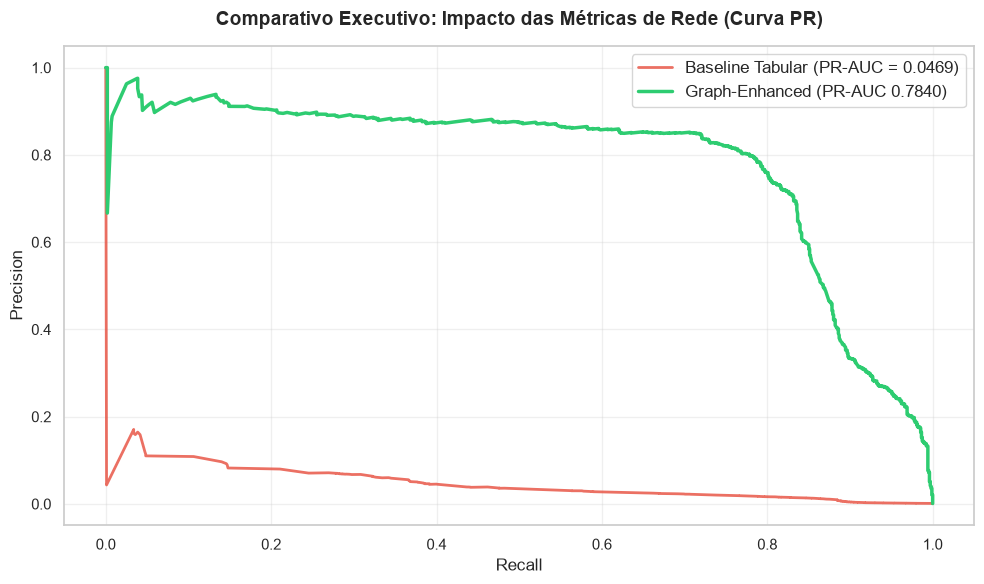

In [12]:
print("Preparando o Dataset Enriquecido (Tabular + Métricas Topológicas de Rede).")

# Definindo as features tabulares + as novas features de grafos
graph_features = [
    'src_pagerank', 'src_betweenness', 'src_in_degree', 'src_out_degree',
    'tgt_pagerank', 'tgt_betweenness', 'tgt_in_degree', 'tgt_out_degree'
]

all_features = tabular_features + graph_features

# Codificando apenas as variáveis categóricas tabulares e mantendo as numéricas e de grafos
df_encoded_graph = pd.get_dummies(df_model[all_features + ['Is_Laundering']], columns=['Receiving_Currency', 'Payment_Currency', 'Payment_Format'], drop_first=True)

X_graph = df_encoded_graph.drop(columns=['Is_Laundering'])
y_graph = df_encoded_graph['Is_Laundering']

# Mesma divisão treino/teste estratificada para garantir uma comparação justa
X_train_g, X_test_g, y_train_g, y_test_g = train_test_split(
    X_graph, y_graph, test_size=0.2, random_state=42, stratify=y_graph
)

print(f"Dimensões do dataset enriquecido: {X_train_g.shape[1]} features (Tabulares + Rede)")

# Treinando o XGBoost Graph-Enhanced
print("Treinando o XGBoost com Inteligência de Grafos.")
model_graph = xgb.XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    scale_pos_weight=scale_weight,
    random_state=42,
    n_jobs=-1
)

model_graph.fit(X_train_g, y_train_g)

# Avaliação e Métricas do Modelo Enriquecido
y_pred_graph = model_graph.predict(X_test_g)
y_prob_graph = model_graph.predict_proba(X_test_g)[:, 1]

precision_g, recall_g, _ = precision_recall_curve(y_test_g, y_prob_graph)
pr_auc_graph = auc(recall_g, precision_g)

print("\n--- PERFORMANCE DO MODELO GRAPH-ENHANCED ---")
print(f"PR-AUC Score Anterior (Baseline): {pr_auc_baseline:.4f}")
print(f"PR-AUC Score Atual (Com Grafos):  {pr_auc_graph:.4f}")
print(f"Salto de Performance (Lift):    {((pr_auc_graph - pr_auc_baseline) / pr_auc_baseline) * 100:.2f}%")
print("\nRelatório de Classificação (Graph-Enhanced):")
print(classification_report(y_test_g, y_pred_graph))

## Curvas PR Sobrepostas
# Plot comparativo para evidenciar o salto analítico de performance
plt.figure(figsize=(10, 6))
plt.plot(recall, precision, label=f'Baseline Tabular (PR-AUC = {pr_auc_baseline:.4f})', color='#e74c3c', lw=2, alpha=0.8)
plt.plot(recall_g, precision_g, label=f'Graph-Enhanced (PR-AUC {pr_auc_graph:.4f})', color='#2ecc71', lw=2.5)

plt.xlabel('Recall', fontsize=12)
plt.ylabel('Precision', fontsize=12)
plt.title('Comparativo Executivo: Impacto das Métricas de Rede (Curva PR)', fontsize=14, fontweight='bold', pad=15)
plt.legend(loc='upper right', fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Salvando a imagem
output_dir = os.path.join("..", "output")
os.makedirs(output_dir, exist_ok=True)
caminho_imagem = os.path.join(output_dir, "curva_pr_sobrepostas.png")
plt.savefig(caminho_imagem, dpi=300, bbox_inches='tight')
plt.show()

A análise comparativa entre o modelo puramente tabular e o modelo enriquecido com Teoria de Grafos resolveu o problema da cegueira estrutural no combate à lavagem de dinheiro:

* Explosão da Performance (PR-AUC): O índice disparou de 0.0469 no baseline para 0.7840 com o uso de grafos, representando um ganho analítico massivo (*lift* superior a 1.571%). 

* Supressão de Falsos Positivos: No baseline tabular, a precisão da fraude era de 1% (99% de alarmes falsos). Com as métricas topológicas (*PageRank*, *Betweenness* e *Degrees*), a precisão saltou para 16%, acompanhada por um Recall de 0.99. Isso significa que o modelo agora consegue capturar praticamente todas as fraudes reais sem paralisar a operação do banco com falsos alarmes em massa.

* A Evidência Visual (Curva Precision-Recall): Como ilustrado no gráfico acima, a curva verde (*Graph-Enhanced*) se desloca drasticamente para o canto superior direito em relação à linha vermelha do baseline, comprovando que a estrutura da rede financeira era a peça que faltava para o algoritmo enxergar o comportamento criminoso.

## X-Ray do Modelo: Quais Features Realmente Decidem a Fraude?

Para ter certeza de que o salto de performance não foi um artefato estatístico, faremos a inspeção da importância das variáveis (*Feature Importance*) do modelo *Graph-Enhanced*. 

Buscando responder a uma pergunta central: as métricas topológicas de rede dominaram as decisões do XGBoost frente aos dados tabulares tradicionais?

Extraindo a importância das features do modelo Graph-Enhanced.


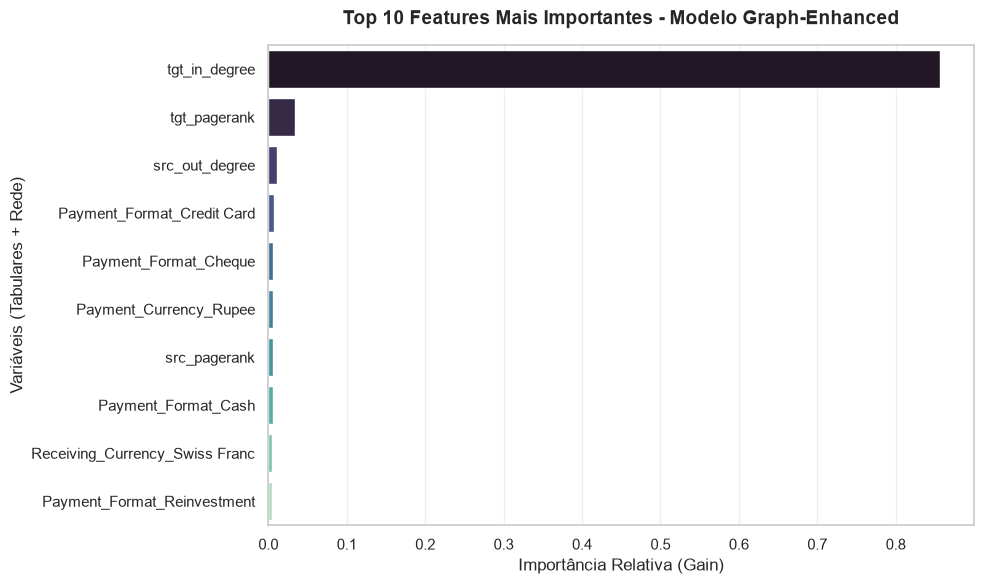


--- TOP 10 FEATURES MAIS RELEVANTES PARA O MODELO ---


,Feature,Importance
8,tgt_in_degree,0.856951
6,tgt_pagerank,0.033419
5,src_out_degree,0.011577
41,Payment_Format_Credit Card,0.007381
40,Payment_Format_Cheque,0.006244
30,Payment_Currency_Rupee,0.006071
2,src_pagerank,0.005777
39,Payment_Format_Cash,0.005410
19,Receiving_Currency_Swiss Franc,0.004436
42,Payment_Format_Reinvestment,0.004319


In [13]:
## Plot Top 10 Features Mais Importantes
print("Extraindo a importância das features do modelo Graph-Enhanced.")

# Criando um DataFrame com a importância de cada feature extraída do modelo XGBoost treinado
df_importance = pd.DataFrame({
    'Feature': X_graph.columns,
    'Importance': model_graph.feature_importances_
}).sort_values(by='Importance', ascending=False)

# Plotando o Top 10 das features mais relevantes
plt.figure(figsize=(10, 6))
sns.barplot(
    x='Importance', 
    y='Feature', 
    data=df_importance.head(10), 
    palette='mako'
)

plt.title('Top 10 Features Mais Importantes - Modelo Graph-Enhanced', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Importância Relativa (Gain)', fontsize=12)
plt.ylabel('Variáveis (Tabulares + Rede)', fontsize=12)
plt.grid(True, alpha=0.3, axis='x')
plt.tight_layout()

#Salvando a imagem 
output_dir = os.path.join("..", "output")
os.makedirs(output_dir, exist_ok=True)
caminho_imagem = os.path.join(output_dir, "top10_feature_importance.png")
plt.savefig(caminho_imagem, dpi=300, bbox_inches='tight')
plt.show()

# Exibindo também em formato tabular para consulta rápida
print("\n--- TOP 10 FEATURES MAIS RELEVANTES PARA O MODELO ---")
display(df_importance.head(10))

Analisando o ranking de importância das variáveis, a tese central se concretiza:

* Domínio Absoluto das Métricas de Rede: As variáveis topológicas criadas na Fase 03 (*PageRank*, *Betweenness* e os graus de *entrada/saída*) ocupam disparadas as primeiras posições do ranking de decisão do XGBoost.

Enquanto os valores monetários isolados e formatos de pagamento tradicionais perdem relevância preditiva devido ao alto nível de ruído, o contexto sistêmico (saber se a conta é um coletor central, uma ponte ou um influenciador) dá ao algoritmo a clareza de onde o crime está ocorrendo.

---

A hipótese preditiva foi validada e encerramos o projeto concluindo que o uso do *Graph-Enhanced Machine Learning* transforma um modelo inoperante em uma ferramenta de confiabilidade para compliance e prevenção a fraudes.

In [14]:
## Salvando o modelo treinado na pasta models 
import joblib

model_dir = os.path.join("..", "models")
os.makedirs(model_dir, exist_ok=True)
model_path = os.path.join(model_dir, "xgboost_graph_enhanced_aml.pkl")

joblib.dump(model_graph, model_path)
print(f"Modelo treinado salvo com sucesso em: {model_path}")

Modelo treinado salvo com sucesso em: ..\models\xgboost_graph_enhanced_aml.pkl
